# Prepare the data

Cuts the three scenes into tiles and burns my outlines into label rasters.

Each scene gets tiled in its own coordinate system. I resample to 0.125 m/px but
do not warp anything onto a shared grid, so the labels sit exactly where I drew
them.

Three files per tile:

```
<scene>_<col>_<row>.tif            image, uint16, raw values
<scene>_<col>_<row>_masks.tif      one integer per boulder
<scene>_<col>_<row>_corridor.tif   1 where I actually looked
index.json                         bounds, fold and counts per tile
```

Runs on the laptop, the source scenes are here. Only the finished archive goes
to the server.

In [1]:
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from shapely.geometry import box

sys.path.insert(0, ".")
import config
from common import tiles, folds, geo

config.check_paths()
config.make_dirs()

print("raw    ", config.RAW)
print("archive", config.ARCHIVE)
print(f"{config.RES} m/px, tile {config.TILE} px = {config.TILE * config.RES:.0f} m, "
      f"overlap {config.OVERLAP} px = {config.OVERLAP * config.RES:.0f} m")

raw     C:\Users\pauls\Desktop\Potsdam_Master\Internship_Uni
archive C:\Users\pauls\Desktop\Potsdam_Master\Internship_Uni\trishuli_netz_data\archive
0.125 m/px, tile 1024 px = 128 m, overlap 256 px = 32 m


## What we are starting from

In [2]:
rows = []
for s, info in config.SCENES.items():
    f = config.image(s)
    with rasterio.open(f) as r:
        rows.append(dict(scene=s, date=info["date"], file=f.name,
                         bands=r.count, dtype=str(r.dtypes[0]),
                         res=round(r.res[0], 4),
                         px=f"{r.width} x {r.height}",
                         upsample=round(r.res[0] / config.RES, 2)))

pd.DataFrame(rows).set_index("scene")

,date,file,bands,dtype,res,px,upsample
scene,,,,,,,
mar,2025-03-03,03Mar2025_epsg32645.tif,1,uint16,0.3271,34606 x 60786,2.62
nov,2025-11-04,04Nov2025_epsg32645.tif,1,uint16,0.4659,26952 x 42912,3.73
feb,2026-02-05,05Feb2026_epsg32645.tif,1,uint16,0.3516,28500 x 55974,2.81


## Outlines

Quick check that these are the files I think they are. `_bloecke` is in each
scene's own coordinates and lines up with its image, `_bloecke_nov` is the same
rows moved into november's system, which is where the valley axis lives.

In [3]:
outlines = {}
rows = []
for s in config.SCENES:
    g = geo.load_outlines(s)
    outlines[s] = g

    nov = geo.load_outlines(s, nov=True)
    assert len(nov) == len(g), f"{s}: row counts differ, the two files are out of sync"

    ok = g.d_m >= config.MIN_DIAMETER
    rows.append(dict(scene=s, mapped=len(g), used=int(ok.sum()),
                     D50=round(g.d_m[ok].median(), 2),
                     D84=round(g.d_m[ok].quantile(0.84), 2),
                     largest=round(g.d_m.max(), 1)))

pd.DataFrame(rows).set_index("scene")

,mapped,used,D50,D84,largest
scene,,,,,
mar,1195,1192,4.64,6.18,25.7
nov,1182,1178,4.64,6.47,21.9
feb,791,791,4.89,6.64,21.4


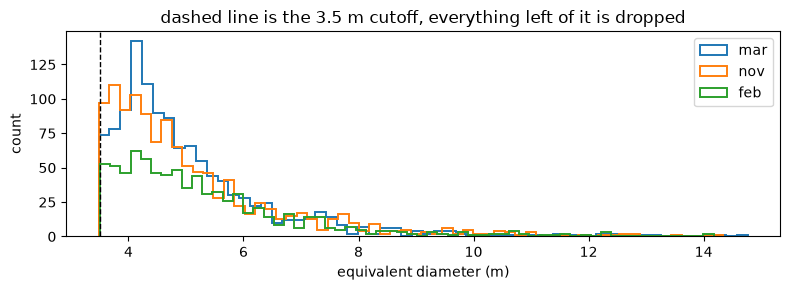

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
for s, g in outlines.items():
    ax.hist(g.d_m[g.d_m < 15], bins=60, histtype="step", lw=1.4, label=s)
ax.axvline(config.MIN_DIAMETER, color="k", ls="--", lw=1)
ax.set_xlabel("equivalent diameter (m)")
ax.set_ylabel("count")
ax.set_title(f"dashed line is the {config.MIN_DIAMETER} m cutoff, everything left of it is dropped")
ax.legend()
plt.tight_layout()
plt.show()

## Overlapping outlines

A label raster holds one integer per pixel, so two outlines that overlap cannot
both survive, the second one overwrites the first. Worth knowing how often that
happens before it quietly eats boulders.

In [5]:
rows = []
for s, g in outlines.items():
    g = g[g.d_m >= config.MIN_DIAMETER].reset_index(drop=True)
    pairs = gpd.sjoin(g[["geometry"]], g[["geometry"]], predicate="overlaps")
    n = len(pairs) // 2
    if n:
        a = g.geometry.values[pairs.index.values]
        b = g.geometry.values[pairs.index_right.values]
        frac = np.array([x.intersection(y).area / x.area for x, y in zip(a, b)])
        rows.append(dict(scene=s, pairs=n,
                         median_pct=round(float(np.median(frac)) * 100, 1),
                         max_pct=round(float(frac.max()) * 100, 1)))
    else:
        rows.append(dict(scene=s, pairs=0, median_pct=0.0, max_pct=0.0))

pd.DataFrame(rows).set_index("scene")

,pairs,median_pct,max_pct
scene,,,
mar,42,1.8,14.3
nov,60,1.7,20.9
feb,24,0.8,32.7


## Folds

Cuts are absolute kilometres along the valley, the same in every scene. The two
ends are always training because one scene is missing there: february starts at
km 7.7, march stops at 24.7.

In [6]:
print("test block ", config.TEST_FROM, "-", config.TEST_TO, "km")
print("fold edges ", config.FOLD_EDGES)
print("always train", config.ALWAYS_TRAIN)

rows = {}
for s in config.SCENES:
    nov = geo.load_outlines(s, nov=True, min_d=config.MIN_DIAMETER)
    rows[s] = folds.summary(nov)

order = ["always_train", "fold1", "fold2", "fold3", "fold4", "test"]
df = pd.DataFrame(rows).T.reindex(columns=order).fillna(0).astype(int)
df.loc["all"] = df.sum()
df

test block  20.9 - 24.8 km
fold edges  [7.5, 11.8, 15.0, 18.1, 20.9]
always train [(0.0, 7.5), (24.8, 26.2)]


,always_train,fold1,fold2,fold3,fold4,test
mar,342,154,189,163,180,166
nov,425,122,166,113,163,189
feb,116,164,117,125,138,131
all,883,440,472,401,481,486


## Build the archive

A few minutes per scene, each one reads and resamples around 150 Mpx.

In [7]:
index = []
for s in config.SCENES:
    print(f"{s}:")
    index += tiles.build_scene(s)

path = tiles.write_index(index)
print(f"\n{len(index)} tiles -> {path}")

mar:
  50 tiles
  100 tiles
  150 tiles
  200 tiles
  250 tiles
  300 tiles
  350 tiles
  400 tiles
  450 tiles
  500 tiles
  537 tiles, 1180 boulders in inner regions, corridor share 40%
nov:
  50 tiles
  100 tiles
  150 tiles
  200 tiles
  250 tiles
  300 tiles
  350 tiles
  400 tiles
  450 tiles
  500 tiles
  550 tiles
  584 tiles, 1169 boulders in inner regions, corridor share 43%
feb:
  50 tiles
  100 tiles
  150 tiles
  200 tiles
  250 tiles
  300 tiles
  350 tiles
  400 tiles
  428 tiles, 775 boulders in inner regions, corridor share 43%

1549 tiles -> C:\Users\pauls\Desktop\Potsdam_Master\Internship_Uni\trishuli_netz_data\archive\index.json


## What came out

In [8]:
idx = pd.DataFrame(tiles.read_index())

per_scene = idx.groupby("scene").agg(
    tiles=("name", "size"),
    with_labels=("n_inner", lambda c: int((c > 0).sum())),
    boulders=("n_inner", "sum"),
    median_per_tile=("n_inner", "median"),
    corridor_share=("corridor", "mean"),
).round(2)
per_scene

,tiles,with_labels,boulders,median_per_tile,corridor_share
scene,,,,,
feb,428,232,775,1.0,0.43
mar,537,324,1180,1.0,0.40
nov,584,317,1169,1.0,0.43


In [9]:
print(idx.groupby("fold").size().to_string())
empty = (idx.n_inner == 0).mean()
print(f"\nempty tiles: {empty:.0%}")
print(f"disk: {sum(f.stat().st_size for f in config.ARCHIVE.glob('*.tif')) / 1e9:.1f} GB")

fold
always_train    382
fold1           286
fold2           192
fold3           207
fold4           186
test            296

empty tiles: 44%
disk: 1.7 GB


## Where the tiles landed

The corridor gets moved into each scene's own system with the offset model, so
it is worth a look that the tiles sit on the river. Zoomed to about 1.4 km,
otherwise you see three thin lines and nothing else. The three panels are the
same stretch of river, the shift between them is the co-registration offset.

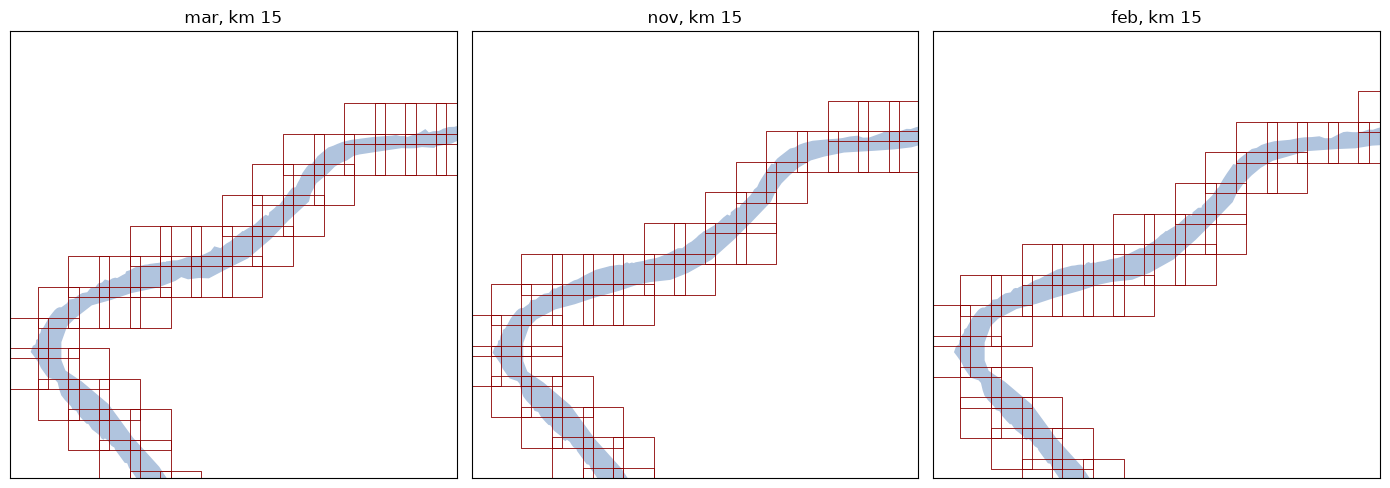

In [10]:
from common.folds import axis
from common.offset import Offset

km, half = 15.0, 700
p = axis().interpolate(km * 1000)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, s in zip(axes, config.SCENES):
    corr = tiles.corridor_in_scene(s)
    q = p if s == config.REFERENCE else Offset(config.VALLEY_AXIS, s).nov_to_scene(p)

    gpd.GeoSeries([corr], crs=config.CRS).plot(ax=ax, color="lightsteelblue")
    boxes = [box(*b) for b in idx.loc[idx.scene == s, "bounds"]]
    gpd.GeoSeries(boxes, crs=config.CRS).plot(
        ax=ax, facecolor="none", edgecolor="darkred", linewidth=0.6)

    ax.set_xlim(q.x - half, q.x + half)
    ax.set_ylim(q.y - half, q.y + half)
    ax.set_title(f"{s}, km {km:.0f}")
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

## Look at a few tiles

Red is the label outline, blue the corridor edge. If these do not line up,
something upstream is wrong.

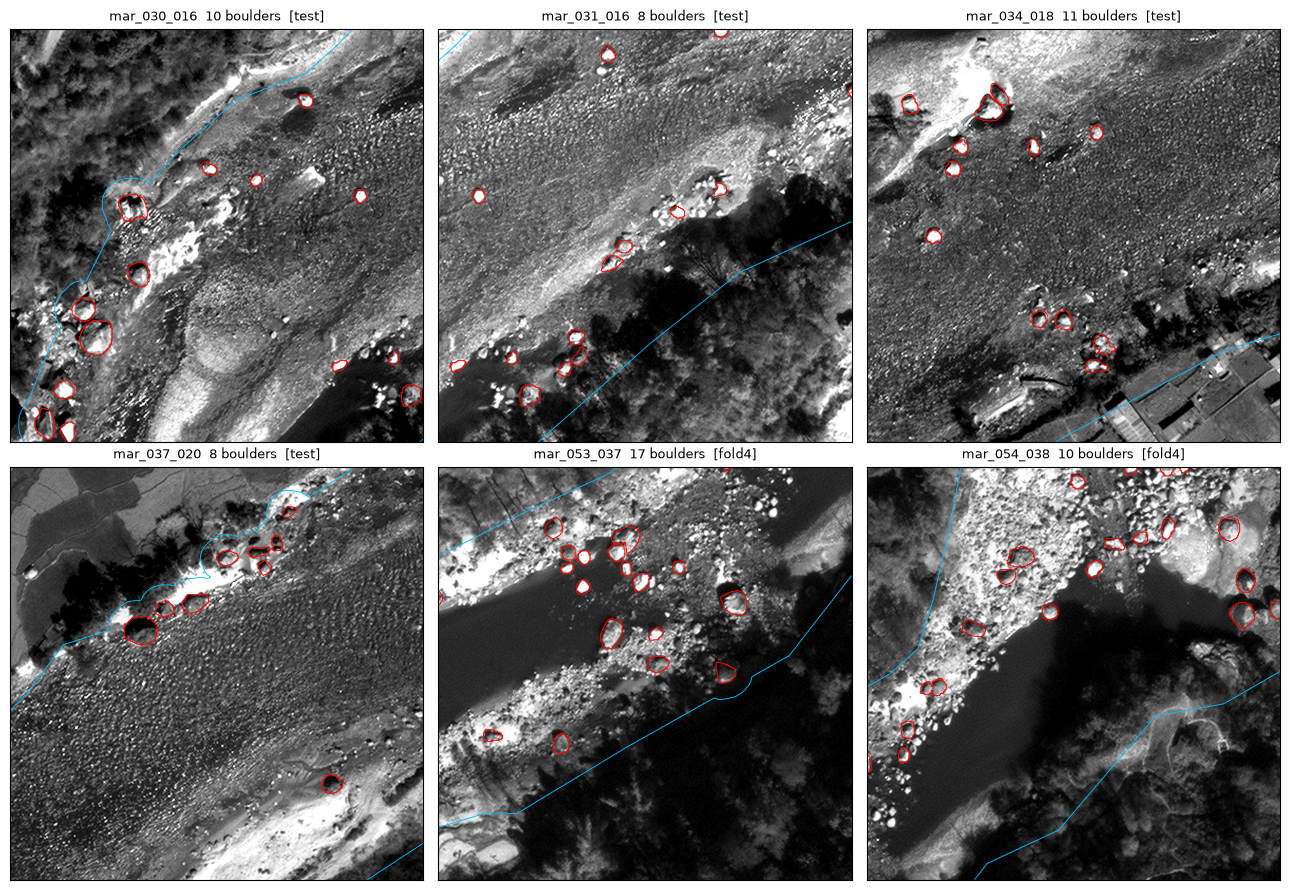

In [11]:
pick = idx[idx.n_inner >= 8].head(6)

fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for ax, (_, t) in zip(axes.ravel(), pick.iterrows()):
    with rasterio.open(config.ARCHIVE / f"{t['name']}.tif") as r:
        img = r.read(1).astype(float)
    with rasterio.open(config.ARCHIVE / f"{t['name']}_masks.tif") as r:
        lab = r.read(1)
    with rasterio.open(config.ARCHIVE / f"{t['name']}_corridor.tif") as r:
        corr = r.read(1)

    good = img > 0
    lo, hi = np.percentile(img[good], config.PERCENTILE)
    ax.imshow(np.clip((img - lo) / max(hi - lo, 1), 0, 1), cmap="gray")
    ax.contour(lab > 0, levels=[0.5], colors="red", linewidths=0.7)
    ax.contour(corr, levels=[0.5], colors="deepskyblue", linewidths=0.6)
    ax.set_title(f"{t['name']}  {t['n_inner']} boulders  [{t['fold']}]", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()